In [28]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf
from statsmodels.tsa.filters.hp_filter import hpfilter

import warnings
from scipy.sparse import SparseEfficiencyWarning
warnings.simplefilter("ignore", SparseEfficiencyWarning)

from Functions import run_multistart, plot_predictive_density, compute_bimodality_series, plot_bimodality, plot_bimodality_and_series, plot_bimodality_and_series_2, plot_predictive_density_ax, plot_predictive_density_simple, shock_analysis
from MLE_Predictive_Density import neg_loglik_student_mar, neg_loglik_student_marx, mar_studentt_pred_density, marx_studentt_pred_density


In [29]:
# Create Linear Trend of Volatility Scaling Function 

def linear_vol_scale(price, window=12):


    price = price.dropna()


    # -------------------------
    # Smooth variance 
    # -------------------------
    var_smooth = price.pow(2).ewm(span=window, adjust=False).mean()

    # -------------------------
    # Clean NaNs
    # -------------------------
    var_smooth = var_smooth.dropna()

    # -------------------------
    # Fit linear trend on LOG variance 
    # -------------------------
    log_var = np.log(var_smooth.values + 1e-8)

    t = np.arange(len(log_var))
    slope, intercept = np.polyfit(t, log_var, 1)

    log_var_trend = intercept + slope * t

    # Back to variance (guaranteed positive)
    var_trend = np.exp(log_var_trend)

    var_trend = pd.Series(var_trend, index=var_smooth.index)

    # -------------------------
    # Volatility 
    # -------------------------
    vol = np.sqrt(var_trend)

    # safety floor (extra robustness)
    vol = vol.clip(lower=1e-8)

    return vol

### Import target series and detrend series with HP filter + linear trend of the volatility scaling

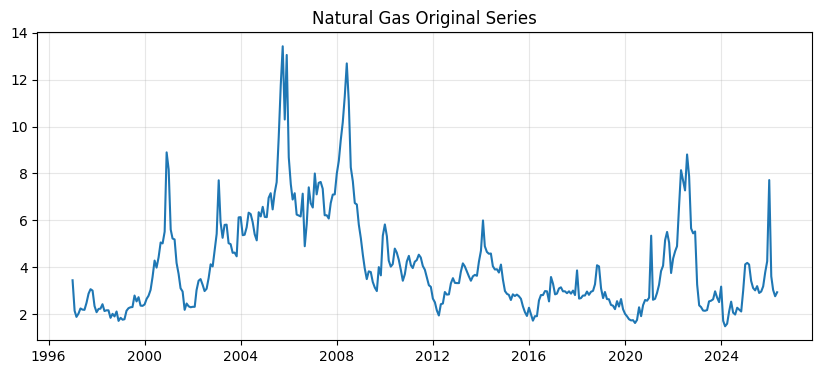

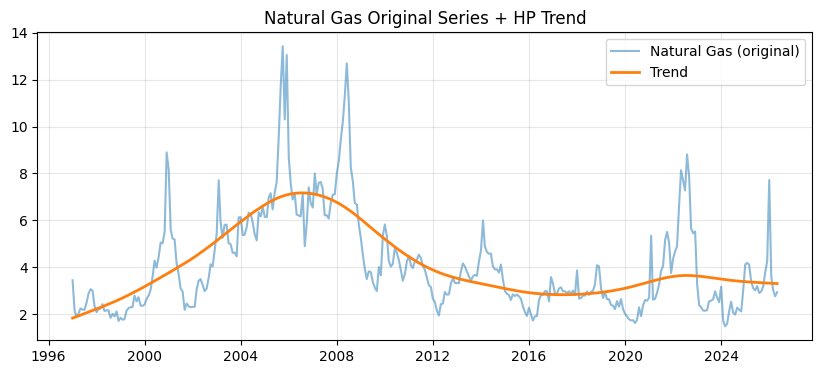

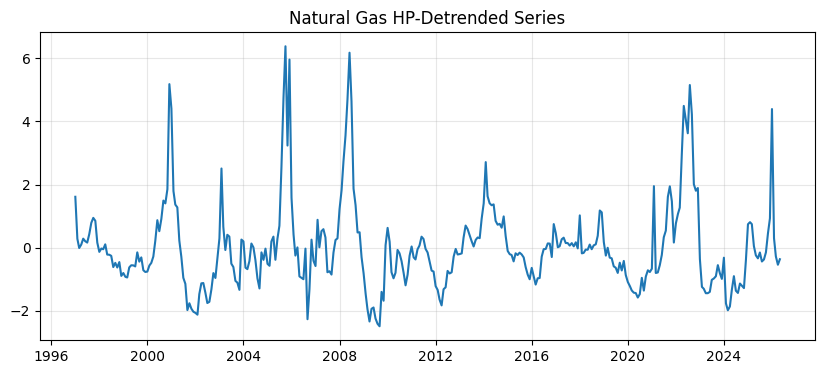

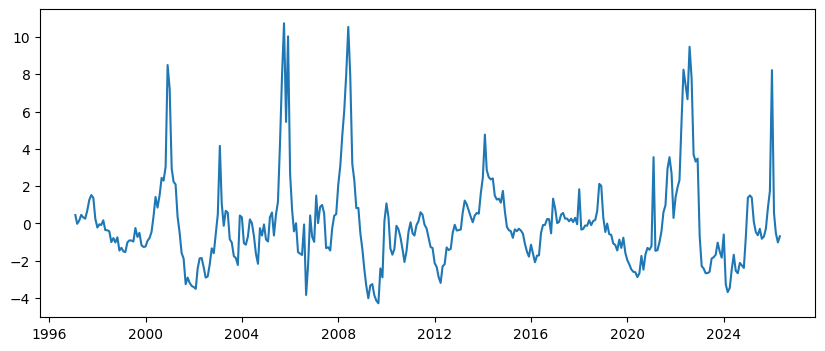

In [30]:
# -------------------------
# DATA
# -------------------------
df_ngas = pd.read_csv("MHHNGSP.csv", parse_dates=["observation_date"])
df_ngas = df_ngas.dropna().set_index("observation_date")


# HP filter + linear trend of the volatility scaling
cycle, trend = hpfilter(df_ngas["MHHNGSP"], lamb=129600)

df_ngas["gas_cycle"] = cycle
df_ngas["gas_trend"] = trend


gas_diff = (df_ngas["gas_cycle"]).diff().dropna()
gas_sigma = linear_vol_scale(gas_diff)


df_ngas["gas_scaled_cycle"]= df_ngas["gas_cycle"]/gas_sigma

# Plot original series
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["MHHNGSP"])
plt.title("Natural Gas Original Series")
plt.grid(alpha=0.3)
plt.show()


# Plot trend decomposition
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["MHHNGSP"], label="Natural Gas (original)", alpha=0.5)
plt.plot(df_ngas.index, df_ngas["gas_trend"], label="Trend", linewidth=2)
plt.title("Natural Gas Original Series + HP Trend")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Plot cycle 
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["gas_cycle"])
plt.title("Natural Gas HP-Detrended Series")
plt.grid(True, alpha=0.3)
plt.show()

# Plot scaled cycle 
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["gas_scaled_cycle"])
#plt.ylabel("HP-detrended price scaled \n by the linear trend \n of the volatility", fontsize=18)
# Increase tick-label font size (axis scales)
#plt.tick_params(axis="both", labelsize=14)
plt.show()


### Extract and Transform Data for Exogeous Variables

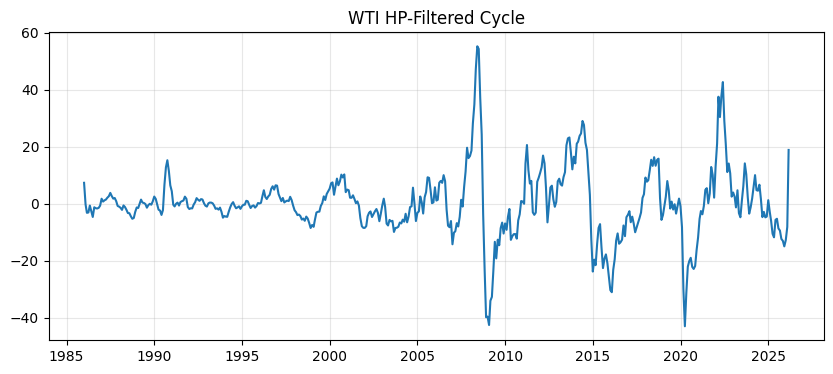

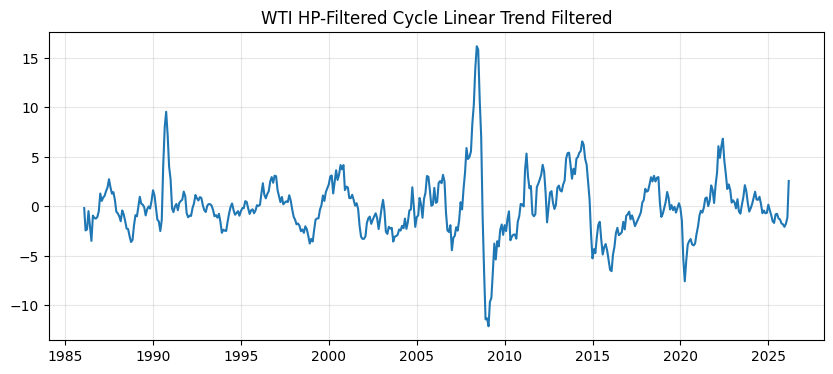

In [31]:
# -------------------------
# WTI DATA
# -------------------------
df_wti = pd.read_csv("MCOILWTICO.csv", parse_dates=["observation_date"])
df_wti = df_wti.dropna().set_index("observation_date")

# HP filter + linear trend of the volatility scaling
wti_cycle, wti_trend = hpfilter(df_wti["MCOILWTICO"], lamb=129600)

wti_diff = (wti_cycle).diff().dropna()
wti_sigma = linear_vol_scale(wti_diff)

wti = wti_cycle/wti_sigma


plt.figure(figsize=(10,4))
plt.plot(wti_cycle)
plt.title("WTI HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(wti)
plt.title("WTI HP-Filtered Cycle Linear Trend Filtered")
plt.grid(alpha=0.3)
plt.show()

In [32]:
# Data and Parameters 
df = pd.concat(
    [
        df_ngas["gas_scaled_cycle"], wti
    ],
    axis=1
).dropna()

df.columns = ["gas_scaled_cycle",  "wti"]
df = df.sort_index()


start_date = "1997-02-01"
end_date   = "2026-03-01"

df = df.loc[start_date:end_date].dropna()


y = df["gas_scaled_cycle"].values
X = df[["wti"]].values

var = [ "wti"]

t1=len(y)-3 # point to calculate predictive density

print(f"Aligned sample: {len(y)} monthly observations")
print(f"Date range: {df.index.min().date()} to {df.index.max().date()}")

#Define Grid for all experiments
grid_min=-50
grid_max=50
ngrid=3000
grid = np.linspace(grid_min, grid_max, ngrid)

#Define points where to calculate bimodality for all experiments
min_t = 2
max_t = len(y) 
times = np.arange(min_t, max_t)


#Parameters for effect of exogenous regressors on bimodality 
std=3
values=30

prominence = 0.01
y_limits=(-10, 15)

Aligned sample: 350 monthly observations
Date range: 1997-02-01 to 2026-03-01


In [33]:
#Import pickle with PSY data

import pickle

with open("psy_ngas.pkl", "rb") as f:
    psy = pickle.load(f)

----
## MAR(1,1) with Student-t innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -489.1380261790015

Estimated parameters:
phi             =     0.2290 (0.0334)
psi             =     0.7936 (0.0235)
sigma           =     0.5206 (0.0411)
nu              =     1.7051 (0.2141)

Hessian condition number:
102.32288347491827

Eigenvalues of Hessian:
[2201.93228156  828.49986544  948.53090717   21.51945104]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -489.138026
AIC:            986.276052
BIC:            1001.684862
R^2:            0.685313

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 12.878816, p-value = 0.000332322
    lag  5: statistic = 25.582401, p-value = 0.000107512
    lag 10: statistic = 36.091015, p-value = 8.11976e-05
    lag 20: statistic = 41.415793, p-value = 0.00329303

Autocorrelation tests (squared standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: s

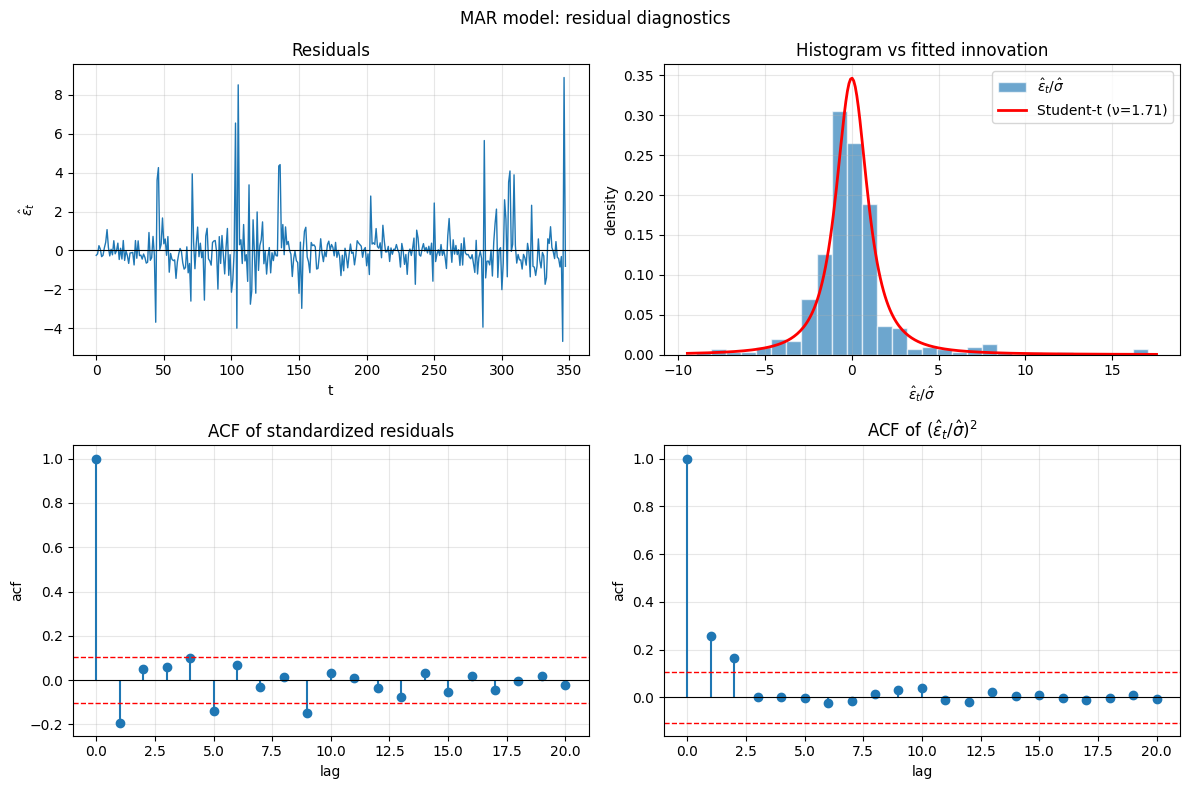

In [34]:
#MLE student-t

param_names = [ "phi", "psi", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None),
    (0.1, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_mar,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

### Predictive Density

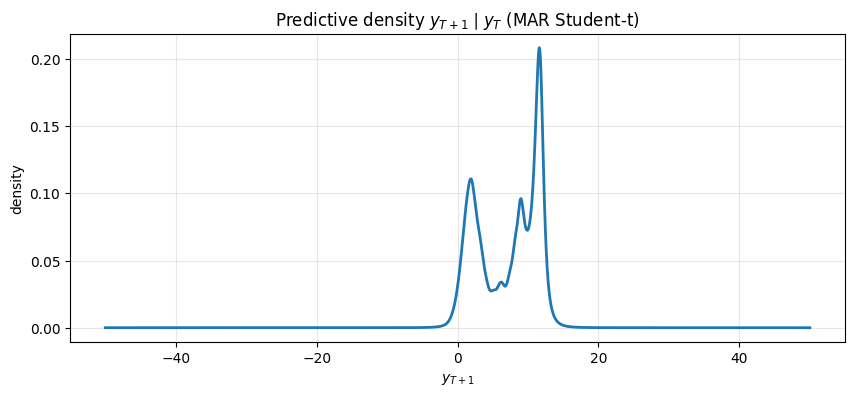

In [35]:
dens = plot_predictive_density(
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid,
    y=y,
    t=t1,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR Student-t)")

### Bimodality

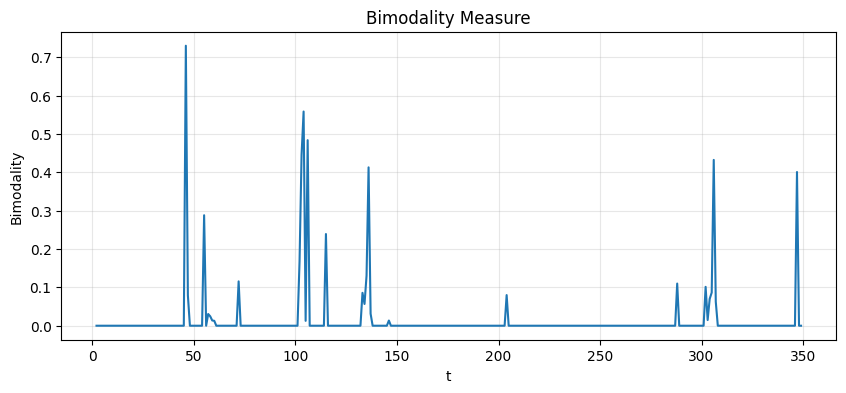

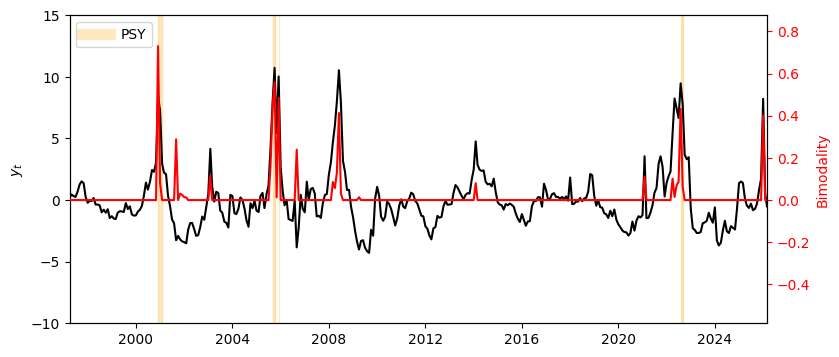

In [36]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_studentt_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


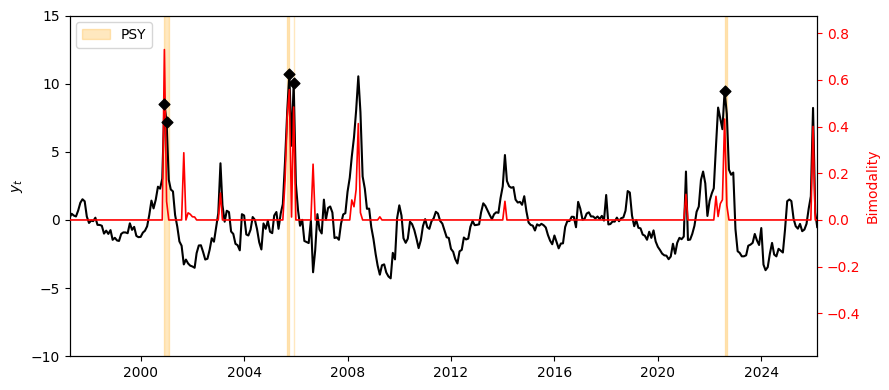

In [37]:
plot_bimodality_and_series_2(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy,
        marker_points=[ 44, 45, 102, 104, 304] 
)

### Predictive Density at selected points

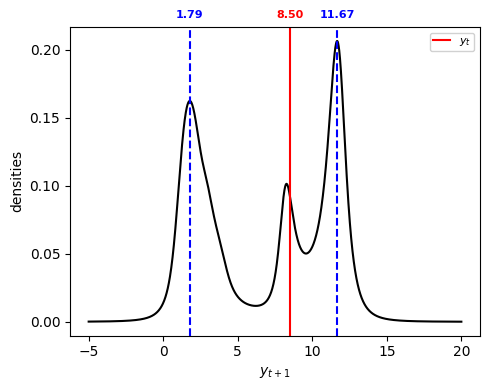

In [38]:
t0 = 46

grid1 = np.linspace(-5, 20, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

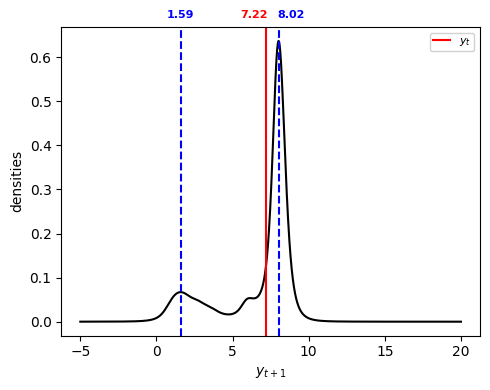

In [39]:
t0 = 47

grid1 = np.linspace(-5, 20, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

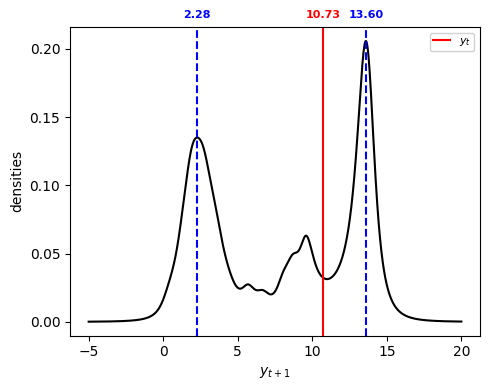

In [40]:
t0 = 104

grid1 = np.linspace(-5, 20, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

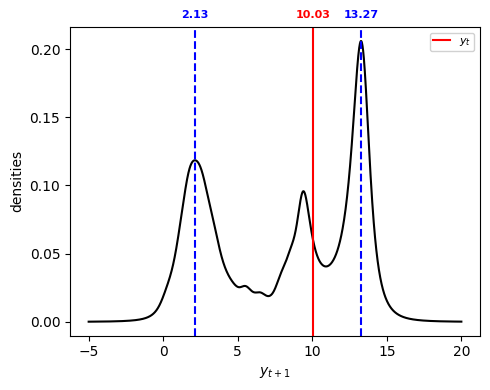

In [41]:
t0 = 106

grid1 = np.linspace(-5, 20, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

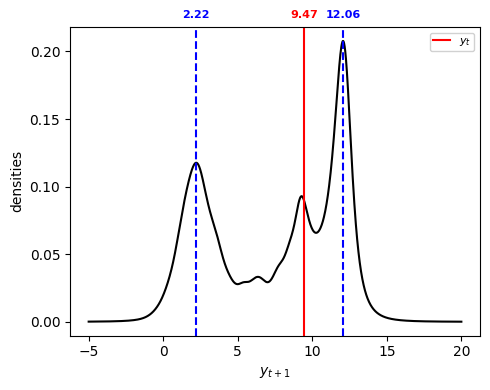

In [42]:
t0 = 306

grid1 = np.linspace(-5, 20, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params   
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

----
## MARX(1,1,3) with Student-t Innovations 

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -488.31951121267224

Estimated parameters:
phi             =     0.2305 (0.0327)
psi             =     0.7685 (0.0321)
beta_wti        =     0.0181 (0.0146)
sigma           =     0.5308 (0.0427)
nu              =     1.7628 (0.2311)

Hessian condition number:
511.0220234507797

Eigenvalues of Hessian:
[9430.57686743 1374.50134673  884.23052161  724.58057112   18.45434528]

MLE diagnostics

--- MARX model diagnostics ---
Log-likelihood: -488.319511
AIC:            986.639022
BIC:            1005.900035
R^2:            0.691423

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 11.821814, p-value = 0.000585408
    lag  5: statistic = 24.506239, p-value = 0.000173494
    lag 10: statistic = 35.118090, p-value = 0.000119201
    lag 20: statistic = 40.350580, p-value = 0.0045095

Autocorrelation tests (squared standardized residuals):
  n       = 348
  Ljung-Box

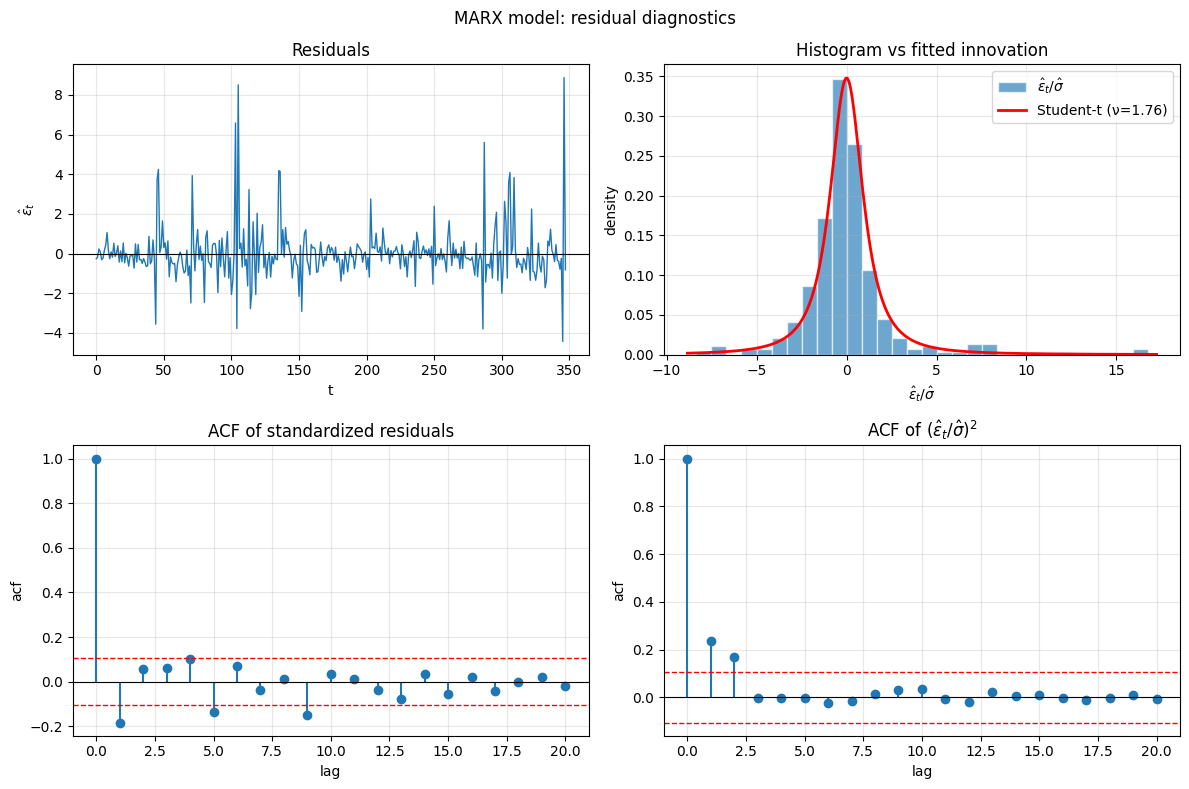

In [43]:
param_names = [ "phi", "psi", "beta_wti", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (1e-6, None),
    (0.1, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_marx,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]


### Sample-Based Predictive Density

$$
\hat l(u_{T+1}\mid u_T, X_T)
=
g(u_T-\psi u_{T+1} - \beta X_T)
\,
\frac{
\sum_{t=1}^{T} g(u_{T+1}-\psi u_t - \beta X_{T+1})
}{
\sum_{t=1}^{T} g(u_T-\psi u_t - \beta X_T)
}
$$

$$
g(e)
=
\frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}
{\Gamma\!\left(\frac{\nu}{2}\right)\sqrt{\nu\pi}\,\sigma}
\left(
1+\frac{e^2}{\nu\sigma^2}
\right)^{-\frac{\nu+1}{2}}
$$

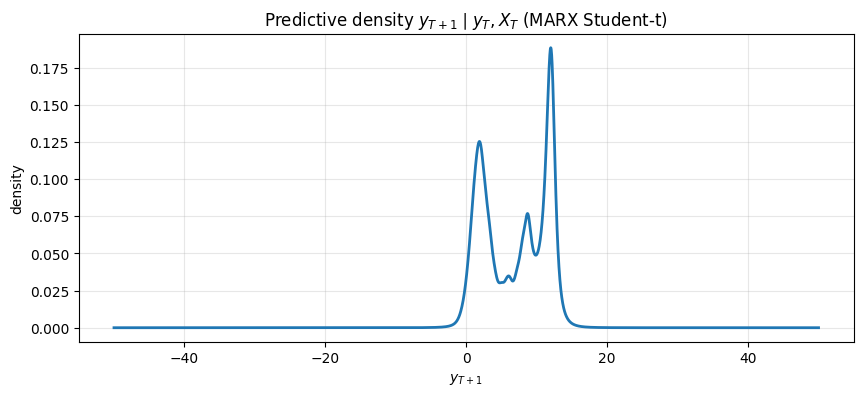

In [44]:
dens = plot_predictive_density(
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t1,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX Student-t)")

### Bimodality

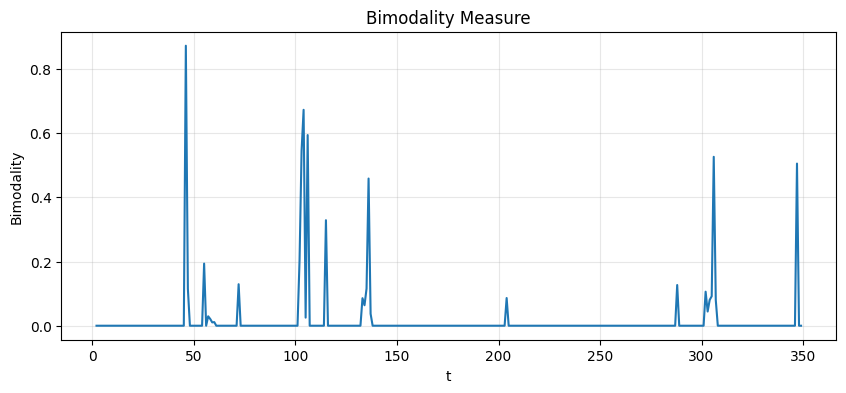

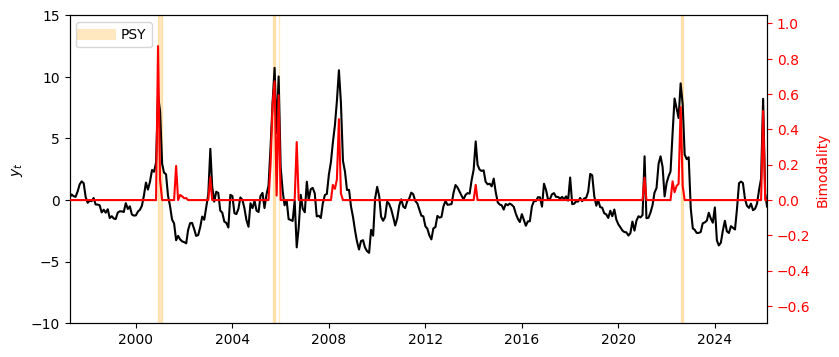

In [45]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_studentt_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


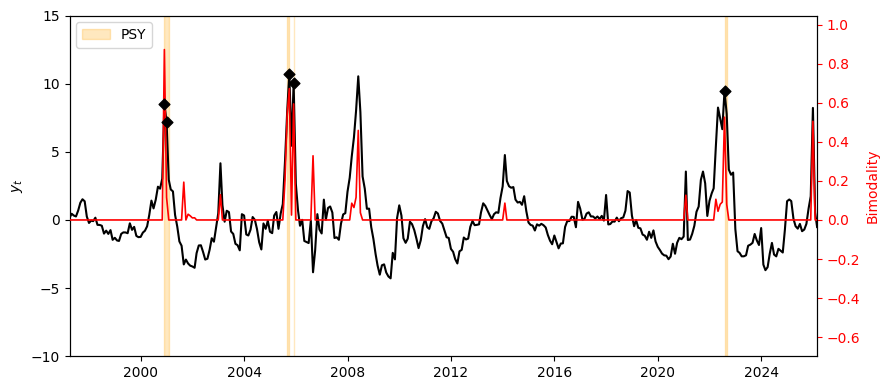

In [46]:
plot_bimodality_and_series_2(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy,
    marker_points=[ 44, 45, 102, 104, 304] 
)

### Predictive Density at selected points

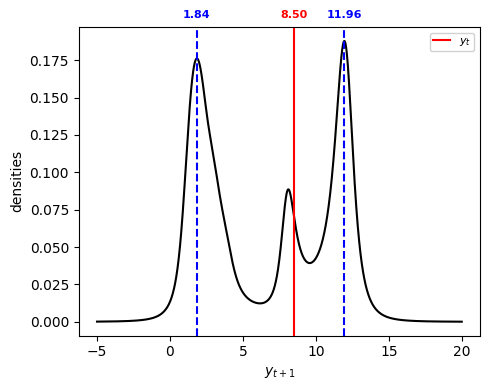

In [47]:
t0 = 46

grid1 = np.linspace(-5, 20, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

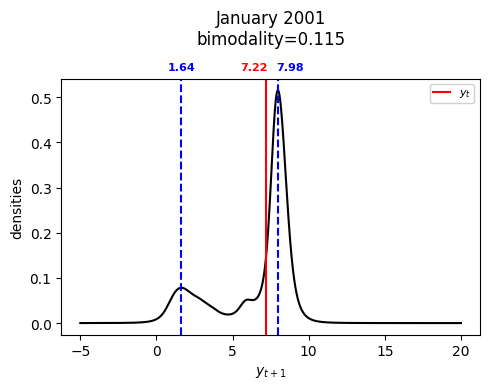

In [48]:
t0 = 47

grid1 = np.linspace(-5, 20, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params,
    title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

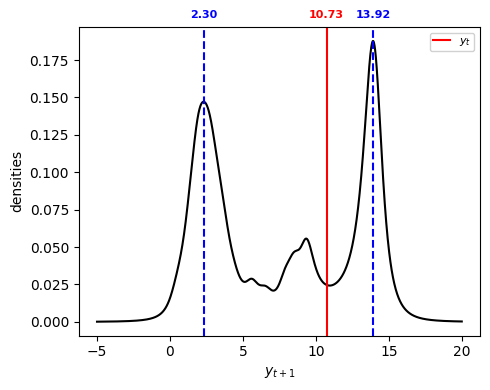

In [49]:
t0 = 104

grid1 = np.linspace(-5, 20, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

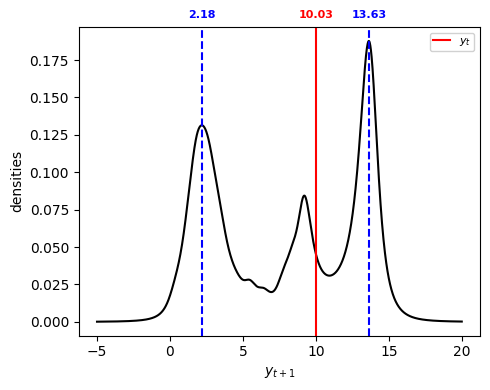

In [50]:
t0 = 106

grid1 = np.linspace(-5, 20, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

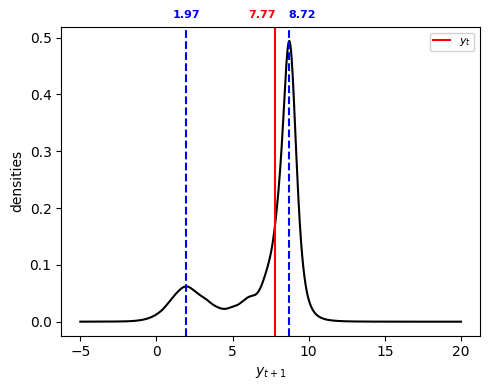

In [51]:
t0 = 307

grid1 = np.linspace(-5, 20, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params   
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

### Predictive Density at and around all points with bimodality

Bimodal times:
[ 46  47  55  57  58  59  60  72 102 103 104 105 106 115 133 134 135 136
 137 204 288 302 303 304 305 306 307 347]


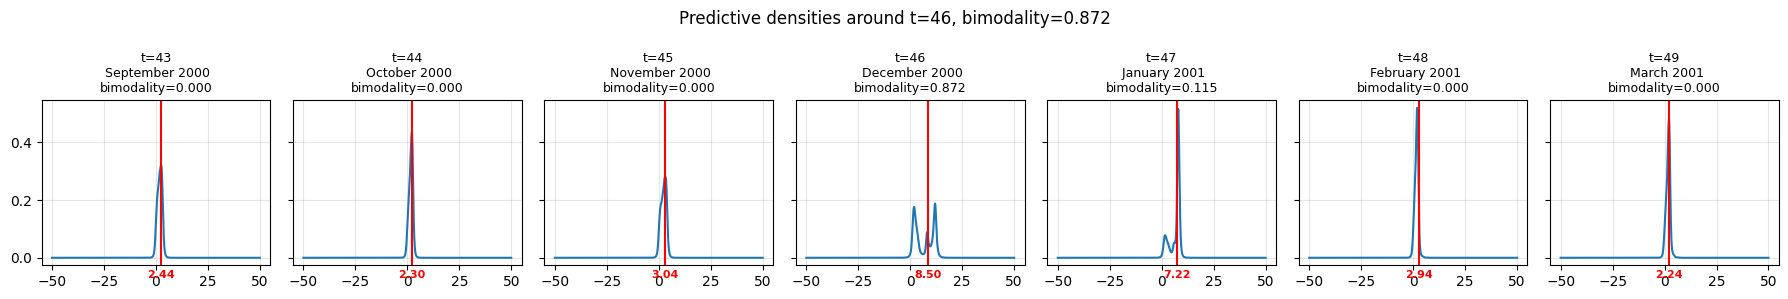

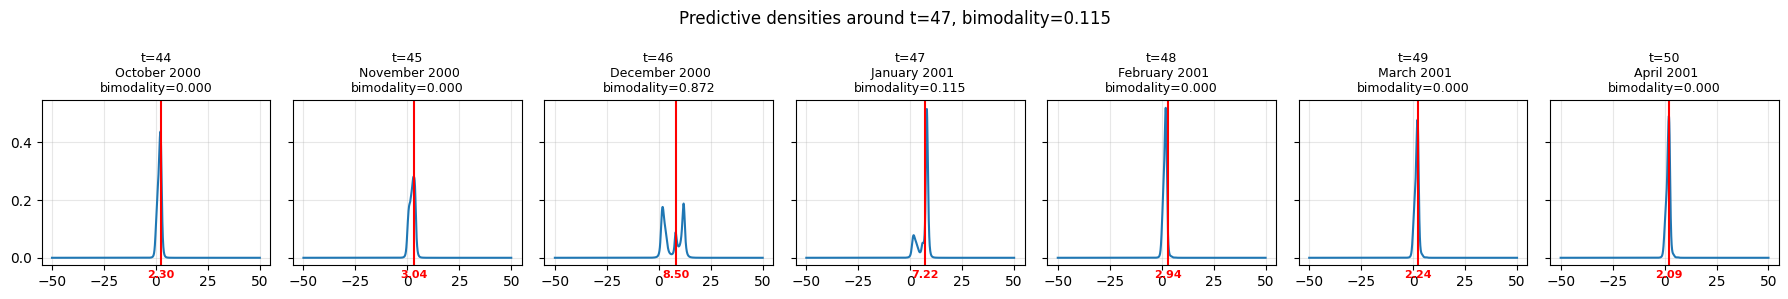

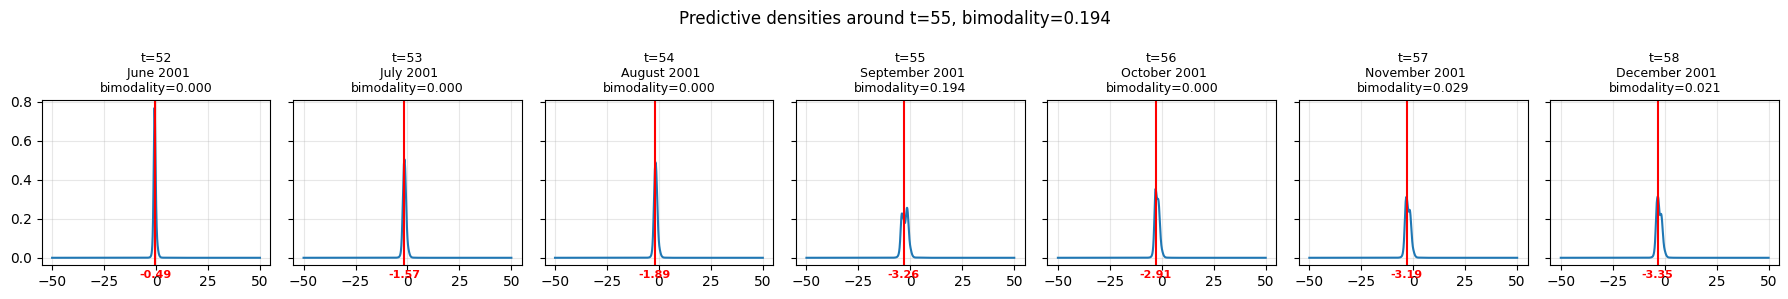

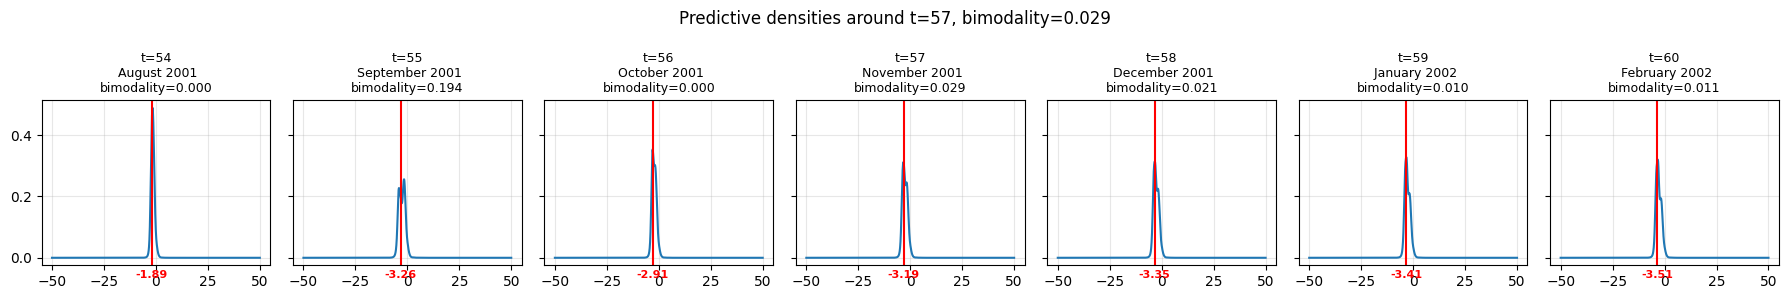

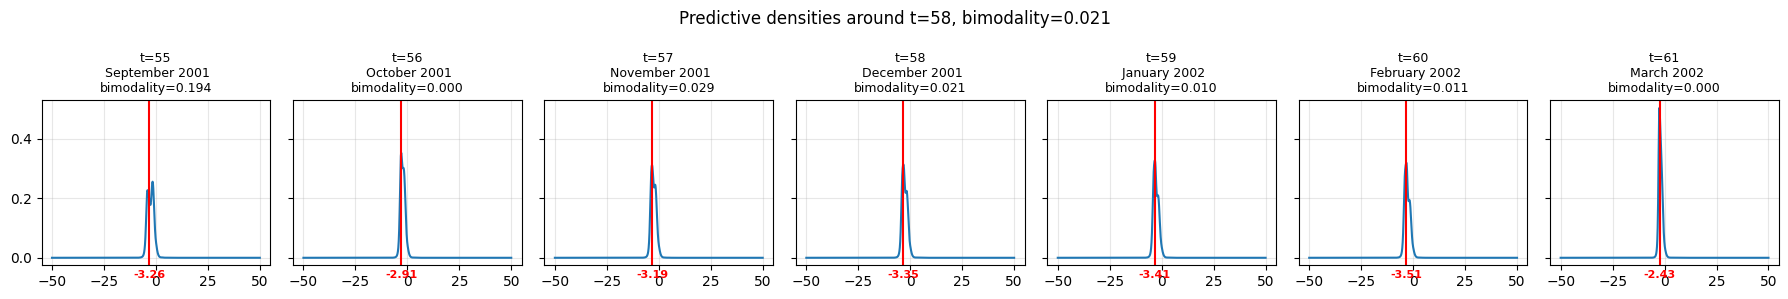

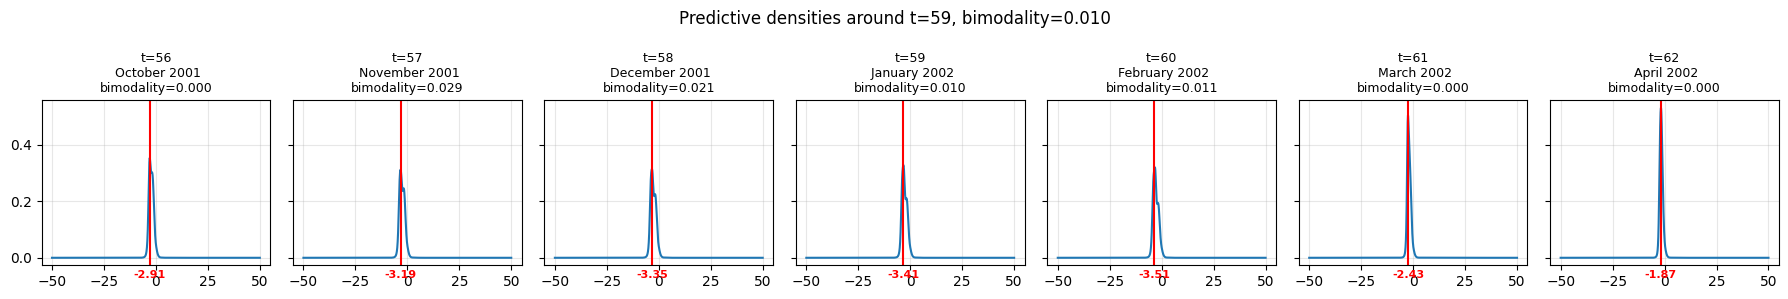

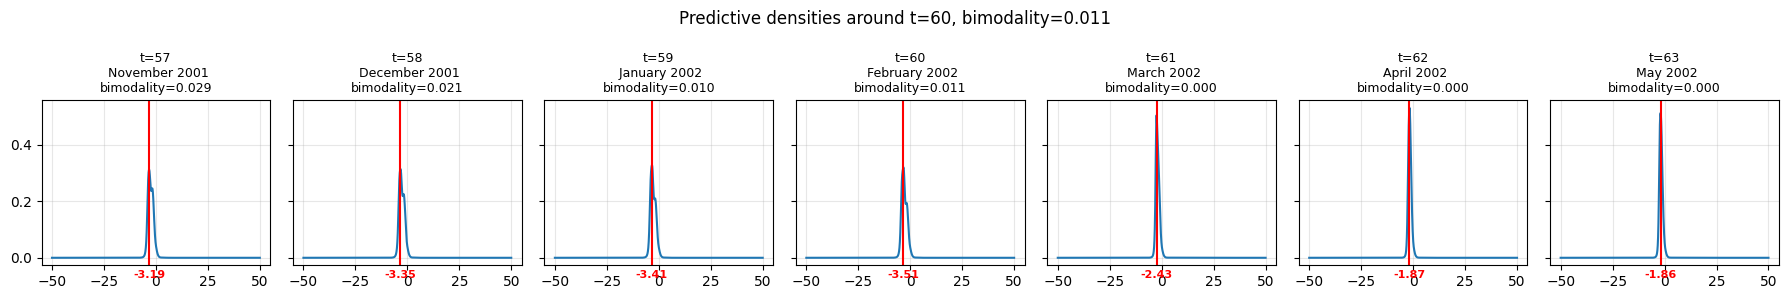

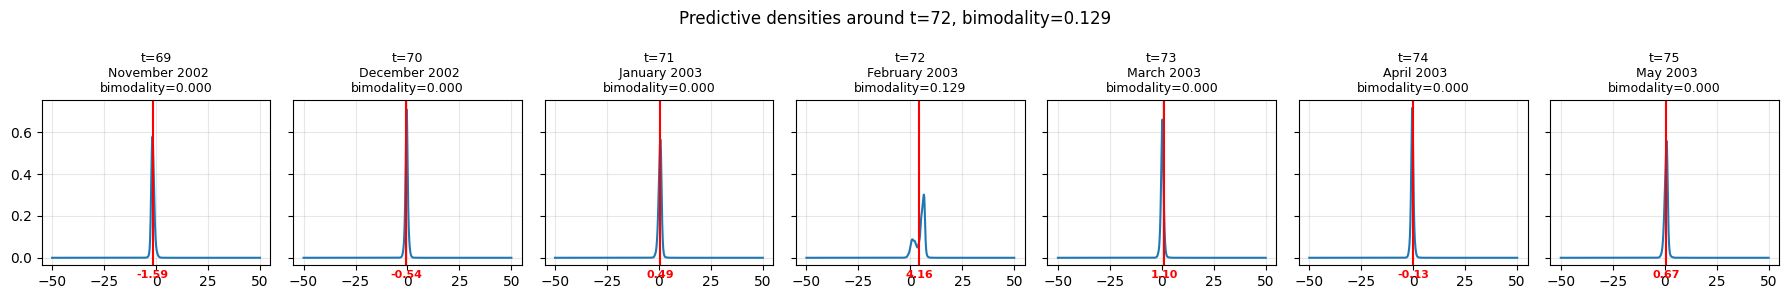

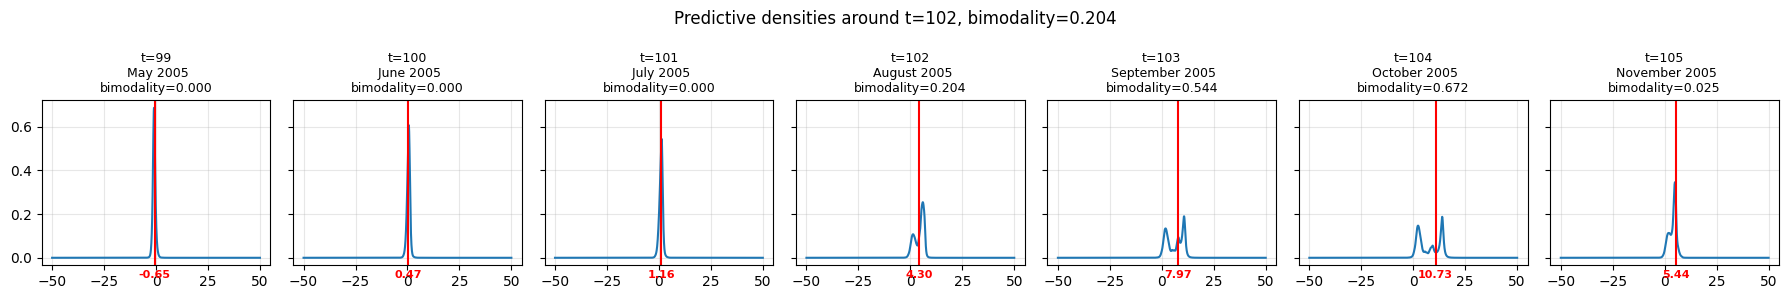

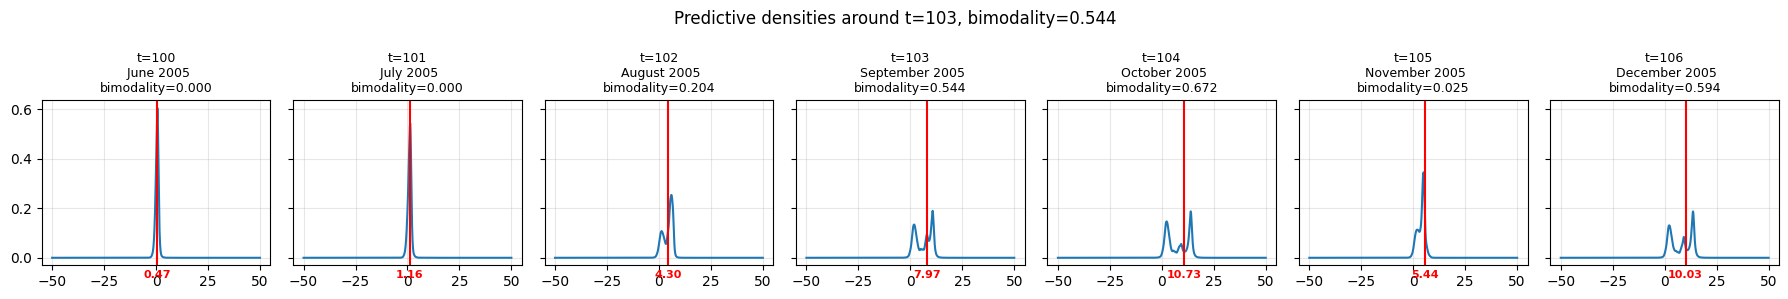

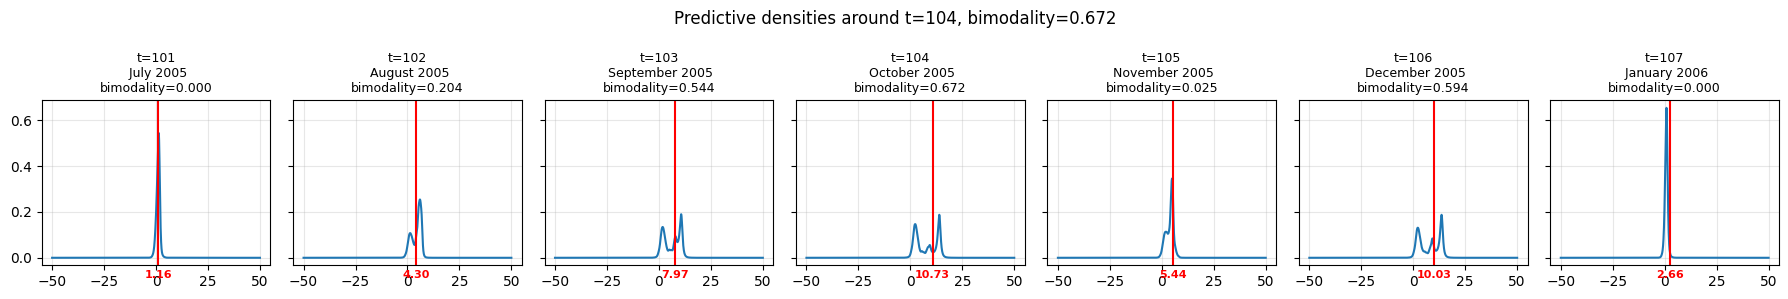

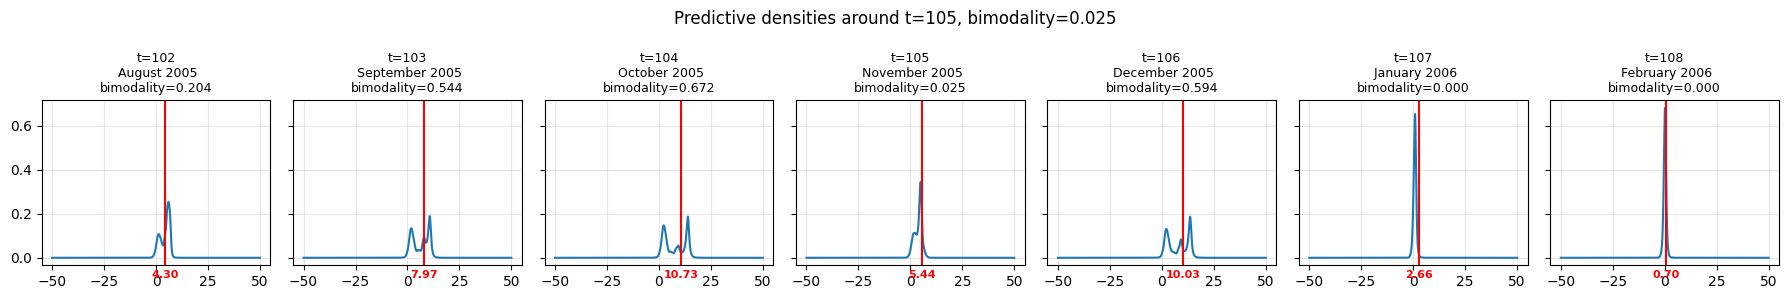

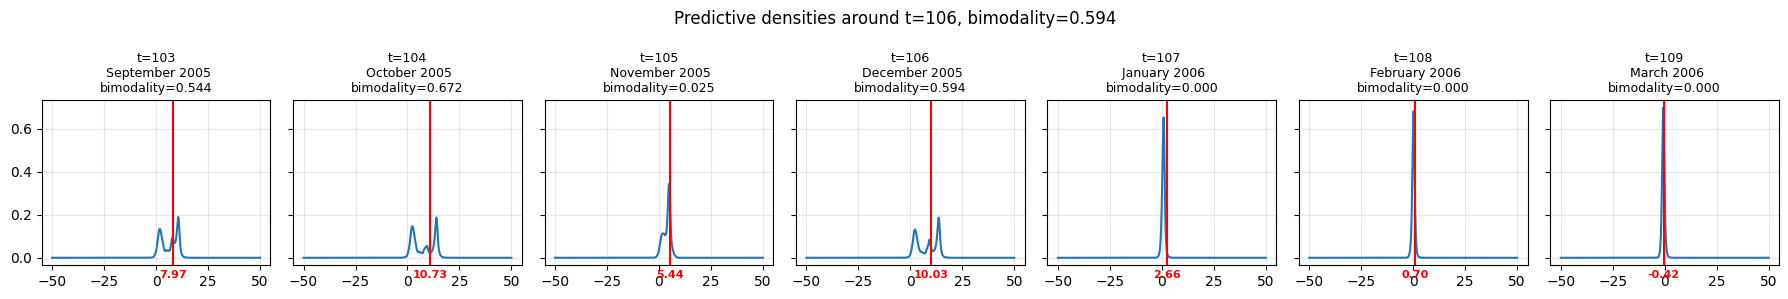

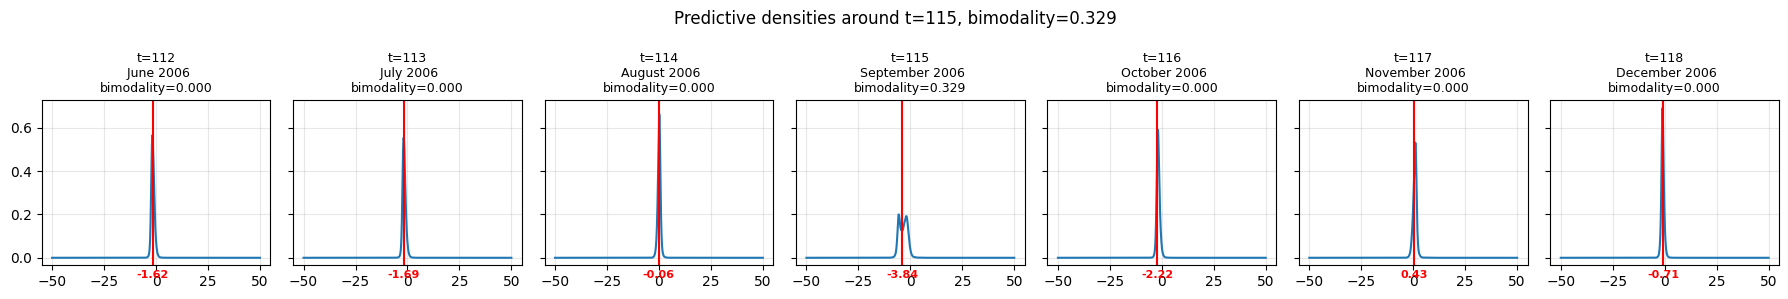

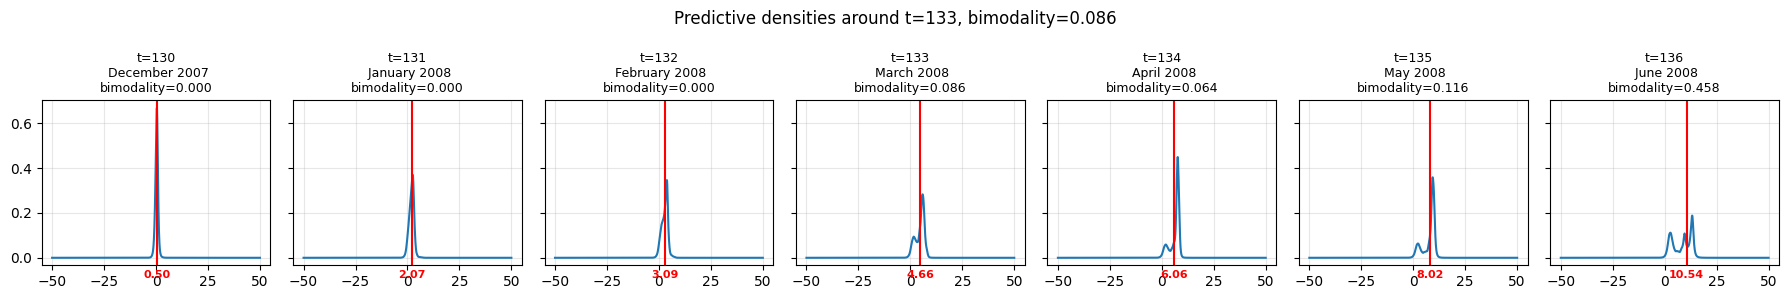

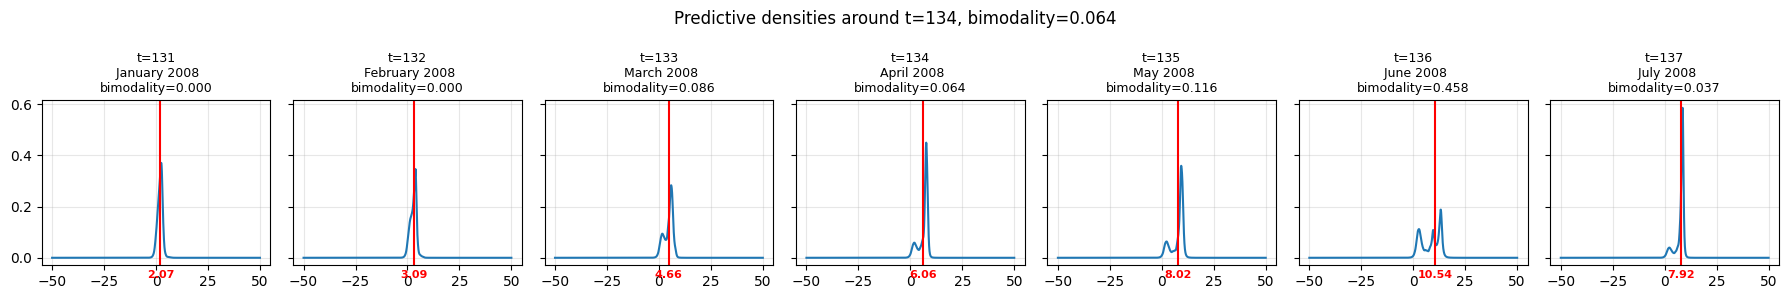

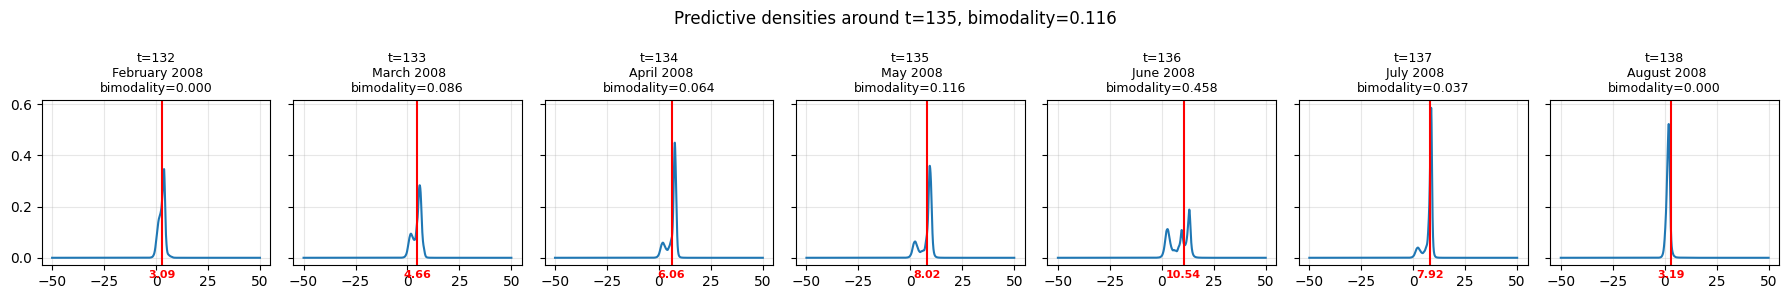

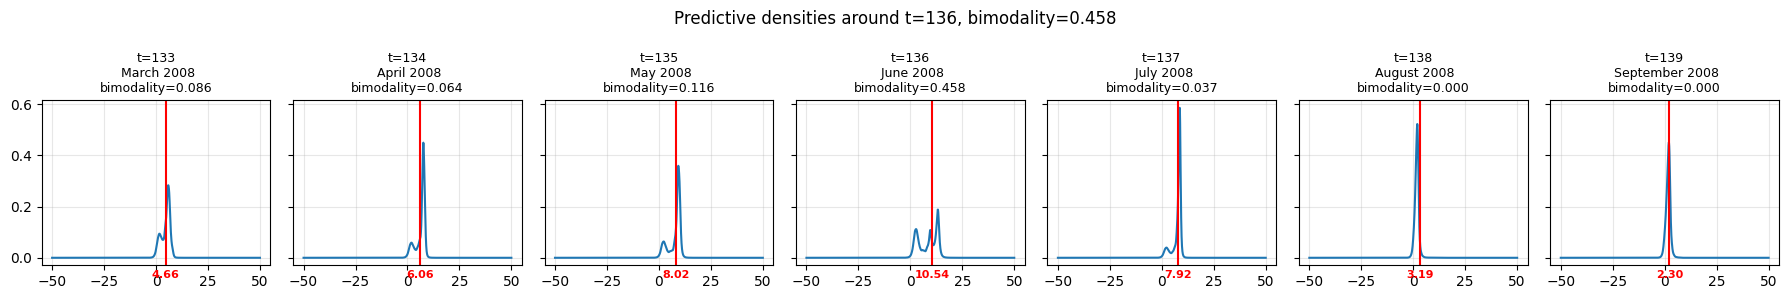

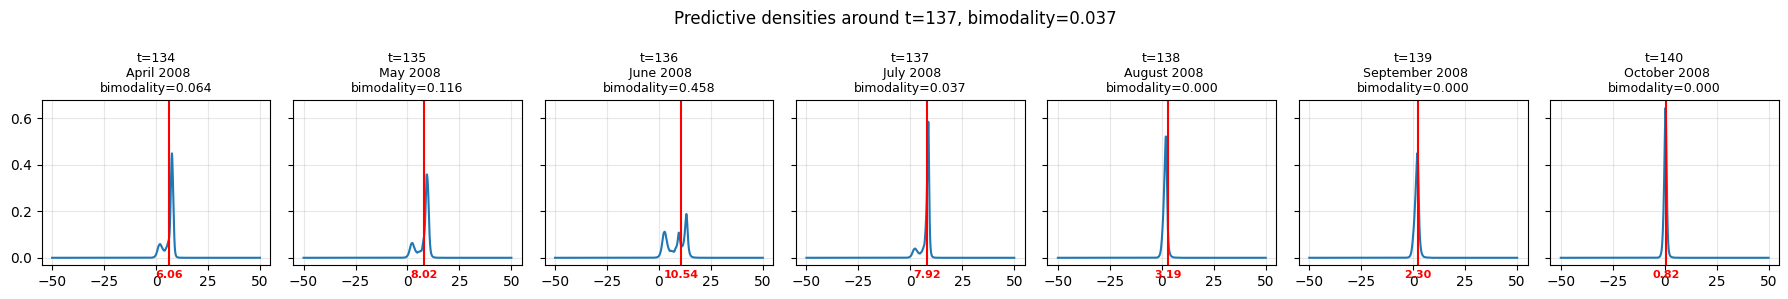

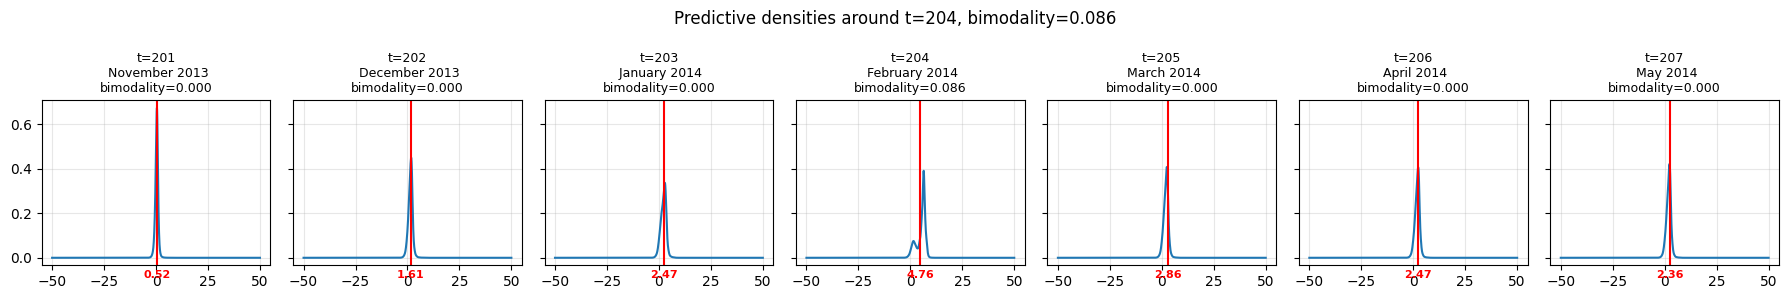

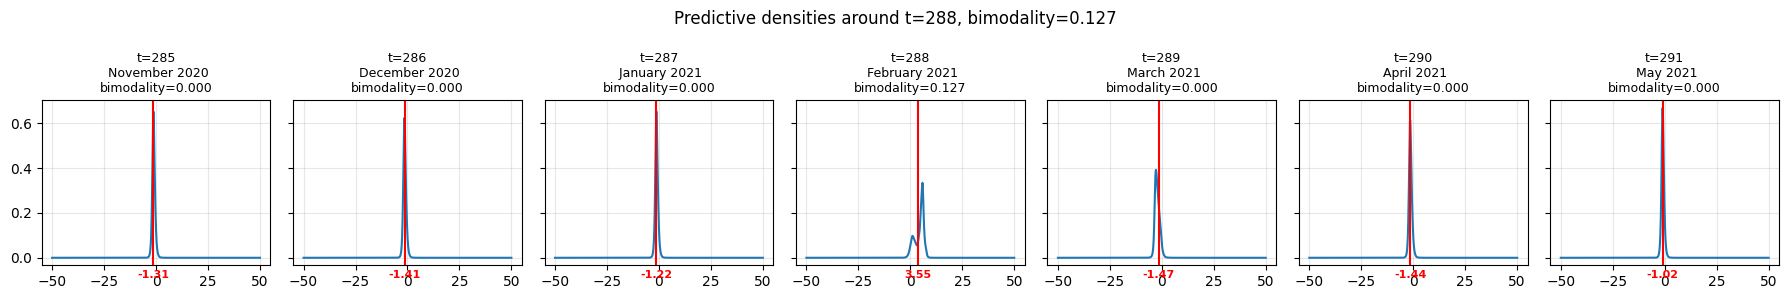

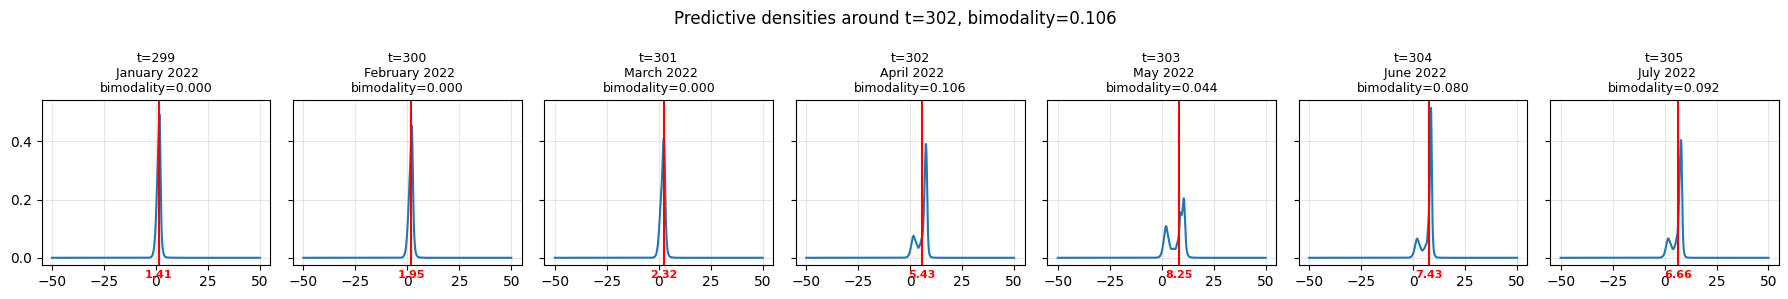

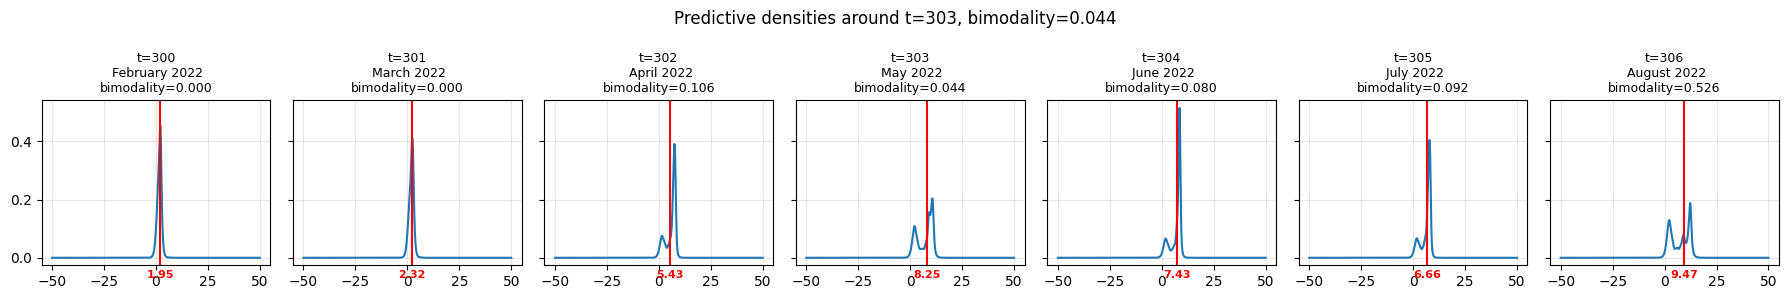

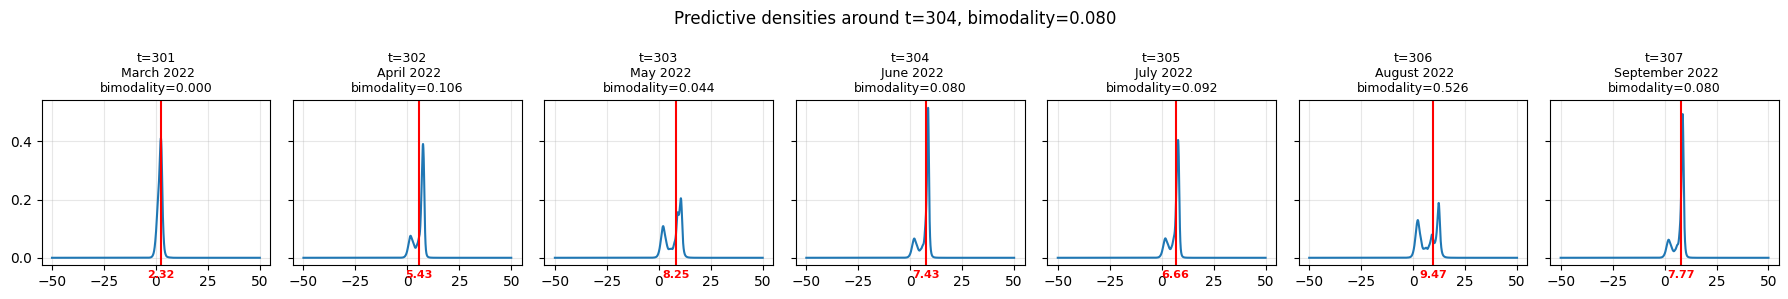

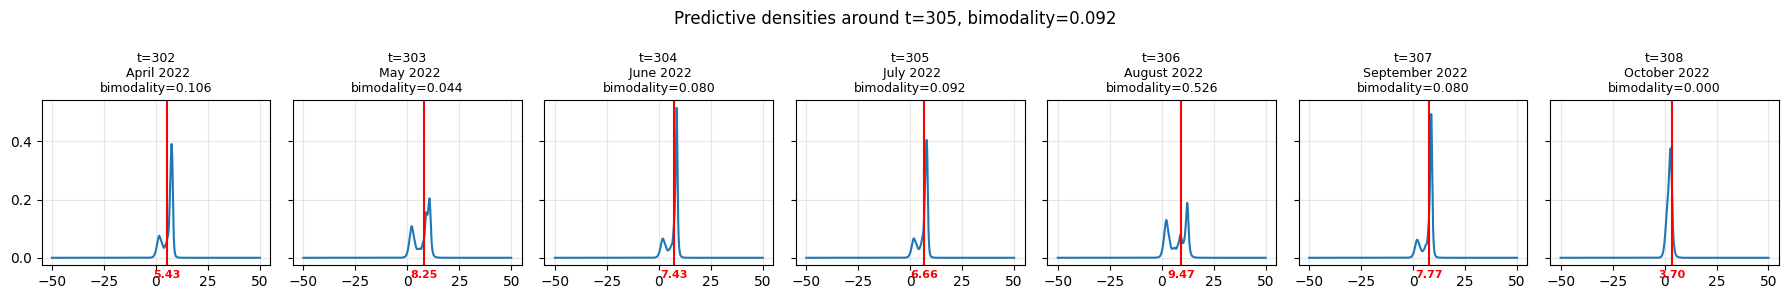

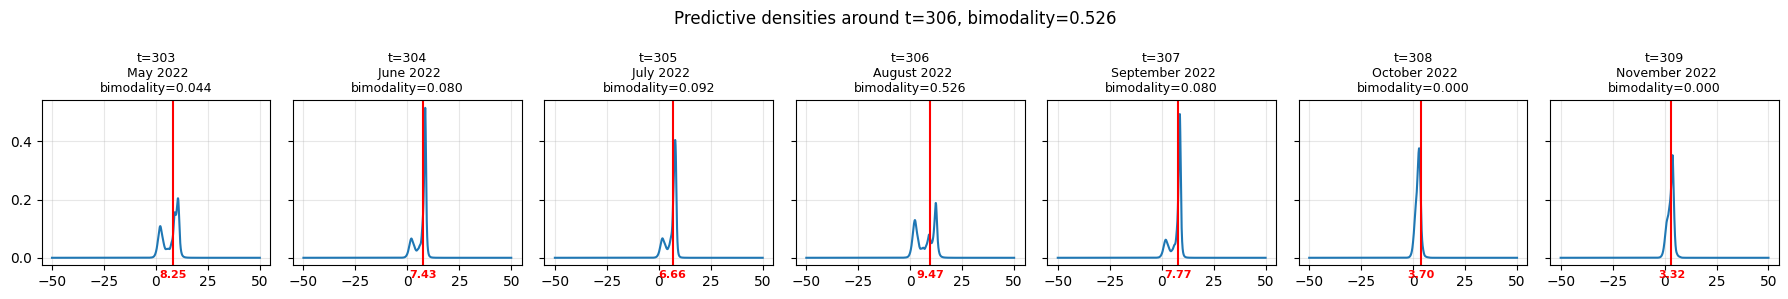

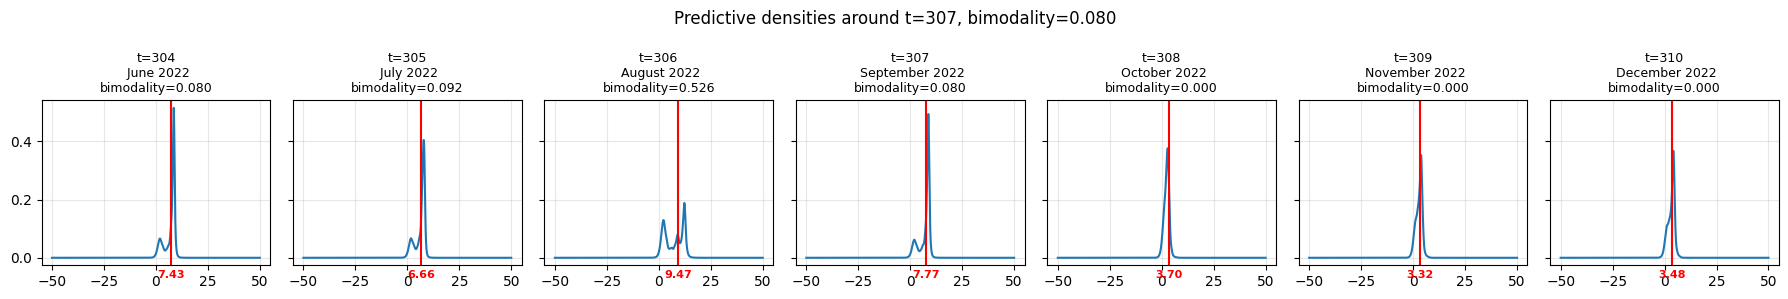

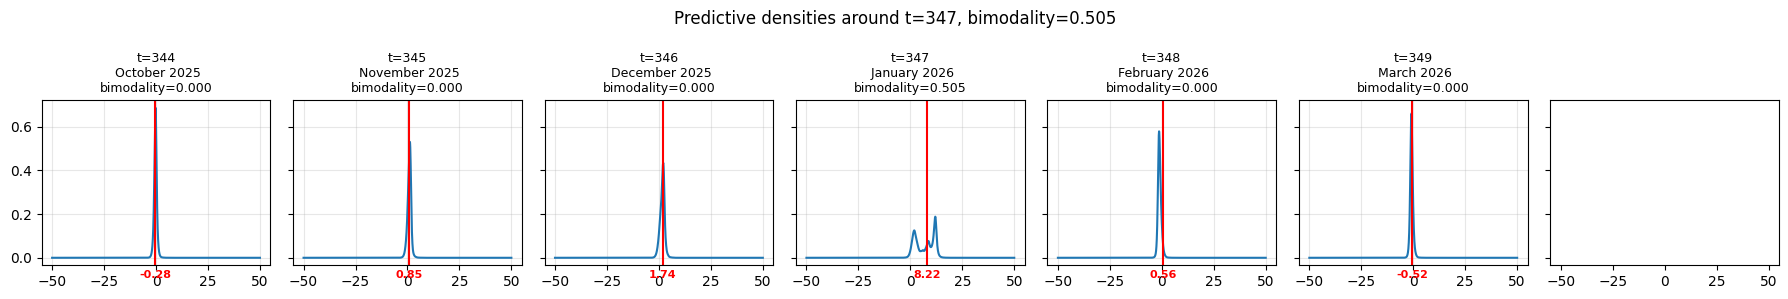

In [52]:
bimodal_times = np.asarray(times)[np.asarray(bimodality_series) != 0]

print("Bimodal times:")
print(bimodal_times)


grid = np.linspace(-50, 50, 3000)

window = 3

for t0 in bimodal_times:

    # Find where this time is located in the times array
    idx = np.where(times == t0)[0][0]

    idx_start = max(0, idx - window)
    idx_end   = min(len(times) - 1, idx + window)

    fig, axes = plt.subplots(1, 7, figsize=(18, 3), sharex=True, sharey=True)
    axes = np.ravel(axes)

    for ax, j in zip(axes, range(idx_start, idx_end + 1)):
        plot_predictive_density_simple(
            ax=ax,
            predictive_density_fn=marx_studentt_pred_density,
            grid=grid,
            y=y,
            X=X,
            t=times[j],
            params=params,
            title=f"t={times[j]}\n {df.index[times[j]].strftime('%B %Y')}\nbimodality={bimodality_series[j]:.3f}",
        )

    plt.suptitle(
        f"Predictive densities around t={t0}, "
        f"bimodality={bimodality_series[idx]:.3f}"
    )
    plt.tight_layout()
    plt.show()

### Bimodality/ Predictive Density changes for different X values

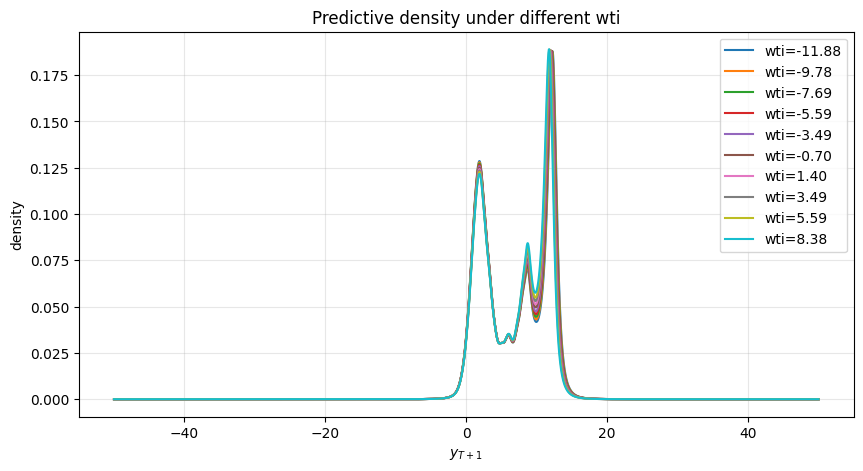

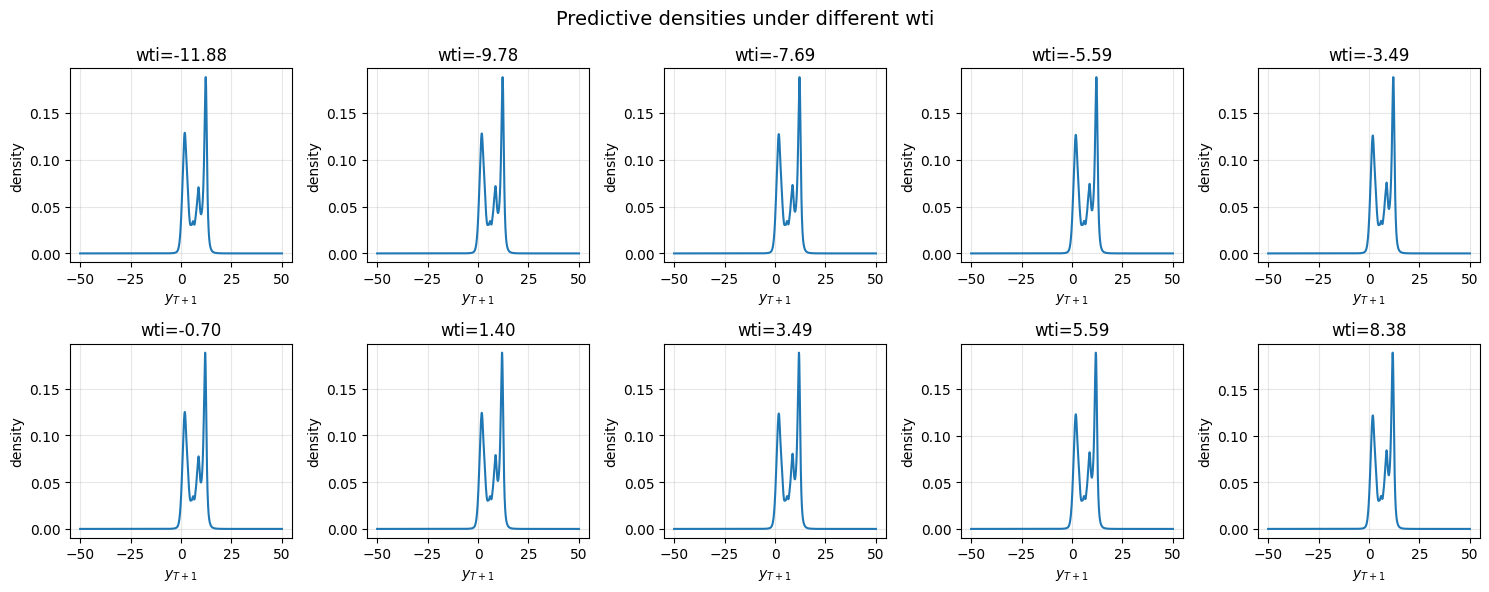

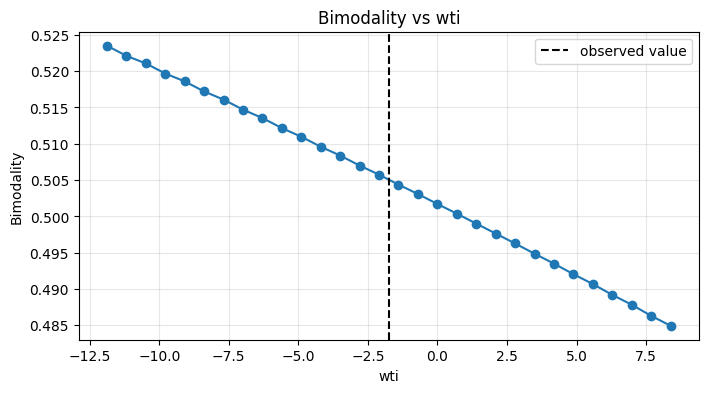

In [53]:
res = shock_analysis(
    var_idx=0,
    X=X,
    y=y,
    params=params,
    predictive_density_fn=marx_studentt_pred_density,
    grid_y=grid,
    n_std=std,
    n_values=values,
    var_names=var,
    t_last=t1,
    prominence_factor=prominence
)